In [4]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

In [5]:
PATH = "../data/processed/statcast_2022.parquet"
raw = pl.read_parquet(PATH)
print(raw.shape)

(775330, 121)


In [ ]:
df = raw.filter(pl.col("description").is_in(["called_strike", "ball"]) & 
                (pl.col("plate_x").is_not_null()) &
                (pl.col("sz_top").is_not_null())
                )
df = df.with_columns((pl.col("is_missed_ball") | pl.col("is_missed_strike")).alias("wrong_call"))
df = df.to_pandas()

In [21]:
print(pd.crosstab(df["description"], [df["is_missed_ball"], df["is_missed_strike"]]))

is_missed_ball         0            1
is_missed_strike       0     1      0
description                          
ball              244692  3980      0
called_strike      85480     0  37102


## Feat Creation/Engr

In [23]:
dx_zone = df['plate_x'].abs() - 17/12/2 #half of plate
dz_zone = np.maximum(df["plate_z"] - df["sz_top"], df["sz_bot"] - df["plate_z"])
df["dist_edge"] = np.maximum(dx_zone,dz_zone)

In [47]:
pitch_mapping = {
    # Fastballs (Velocity & Movement variations)
    "FF": "Fastball",  # Four-Seam Fastball
    "SI": "Fastball",  # Sinker
    "FC": "Fastball",  # Cutter
    "FA": "Fastball",  # Other Fastball

    # Sliders (Horizontal movement)
    "SL": "Slider",    # TSlider
    "ST": "Slider",    # Sweeper
    "SV": "Slider",    # Slurve

    # Curveballs
    "CU": "Curveball", # Traditional Curveball
    "KC": "Curveball", # Knuckle-Curve
    "CS": "Curveball", # Slow Curve

    # Changeups
    "CH": "Changeup",  # Traditional Changeup
    "FS": "Changeup",  # Splitter (Finger-Split)
    "FO": "Changeup",  # Forkball
    "SC": "Changeup",  # Screwball (Fades opposite of a slider)

    # Junk
    "EP": "Junk",      # Eephus (Ultra-slow utility pitch)
    "KN": "Junk"       # Knuckleball
}

df["pitch_cat"] = df["pitch_type"].map(pitch_mapping)
df["count"] = df["balls"].astype(str) + "-" + df["strikes"].astype(str)
df["same_hand"] = (df["stand"] == df["p_throws"]).astype(int)
df["wrong_call"] = df["is_missed_ball"] | df["is_missed_strike"]
df['call'] = df['description']
df["month"] = pd.to_datetime(df["game_date"]).dt.month

is_missed_ball      0.099937
is_missed_strike    0.010720
dtype: float64


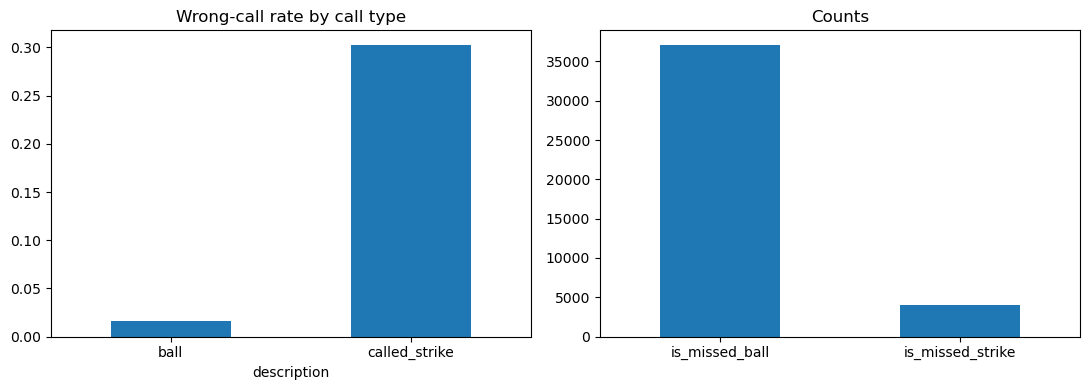

In [34]:
resp = ["is_missed_ball", "is_missed_strike"]
print(df[resp].mean())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.groupby("description")["wrong_call"].mean().plot.bar(ax=ax[0], rot=0, title="Wrong-call rate by call type")
df[resp].sum().plot.bar(ax=ax[1], rot=0, title="Counts")
plt.tight_layout()

release_speed        0.000
release_spin_rate    0.006
release_extension    0.004
release_pos_x        0.000
release_pos_z        0.000
pfx_x                0.000
pfx_z                0.000
plate_x              0.000
plate_z              0.000
sz_top               0.000
sz_bot               0.000
spin_axis            0.006
arm_angle            0.045
dist_edge            0.000
dtype: float64


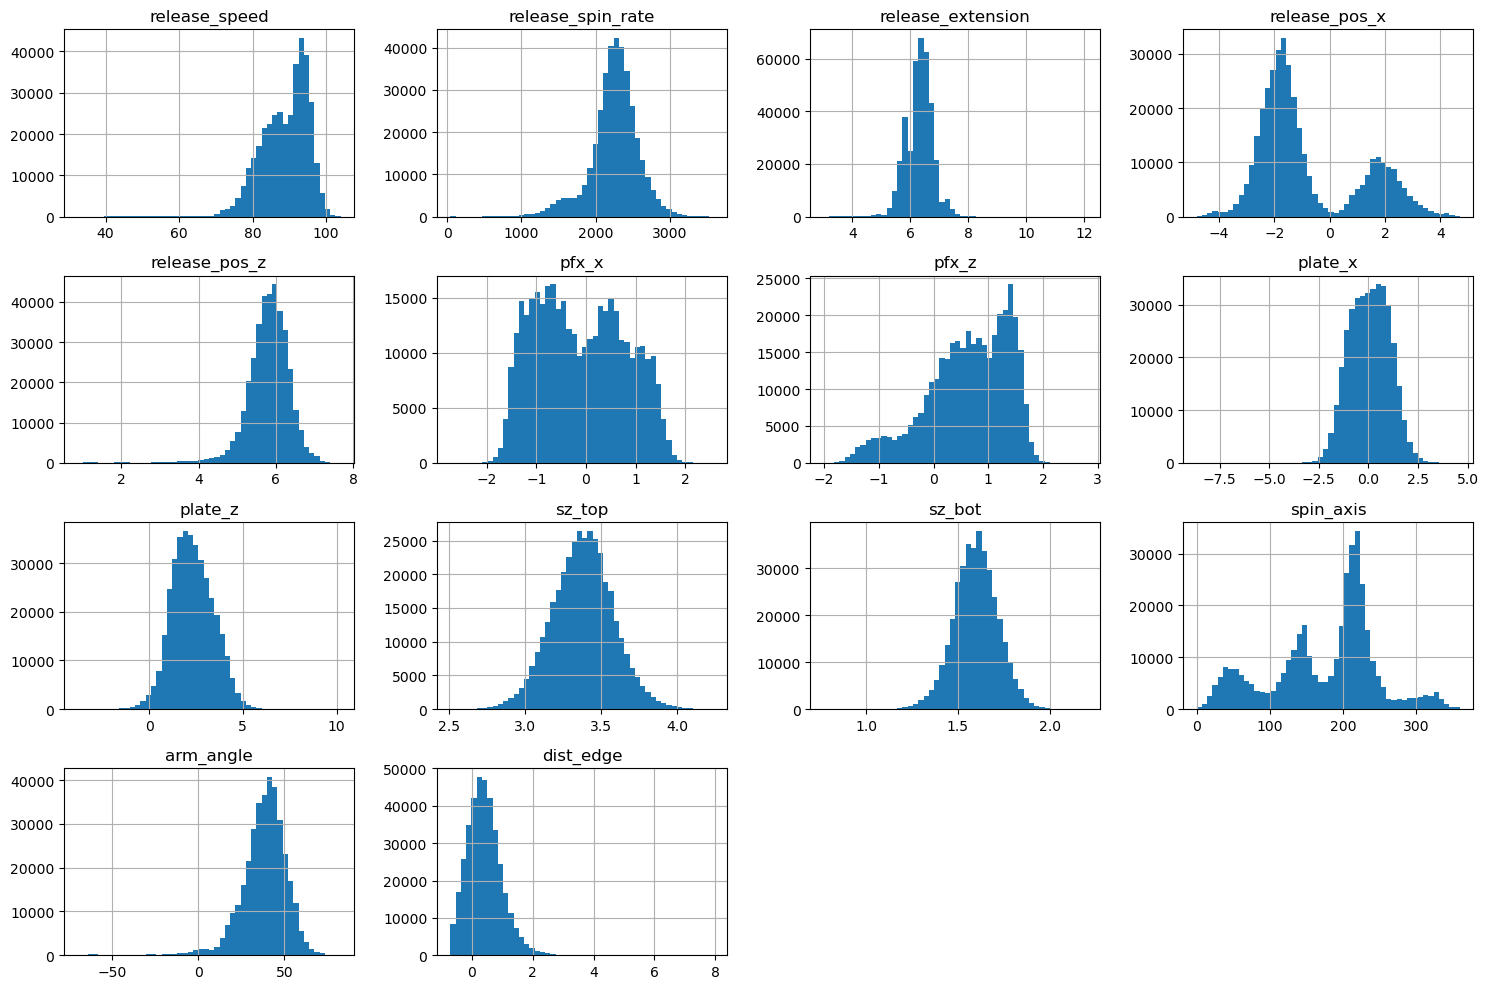

In [35]:
num_feats = ["release_speed","release_spin_rate","release_extension","release_pos_x","release_pos_z",
             "pfx_x","pfx_z","plate_x","plate_z","sz_top","sz_bot","spin_axis","arm_angle","dist_edge"]
df[num_feats].hist(bins=50, figsize=(15, 10)); plt.tight_layout()
print(df[num_feats].isna().mean().round(3))

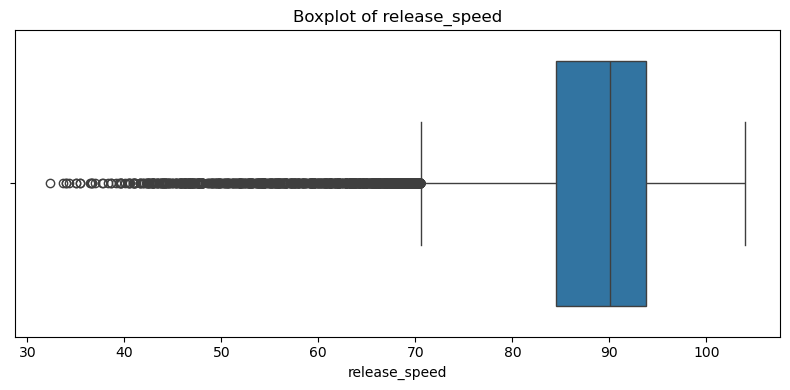

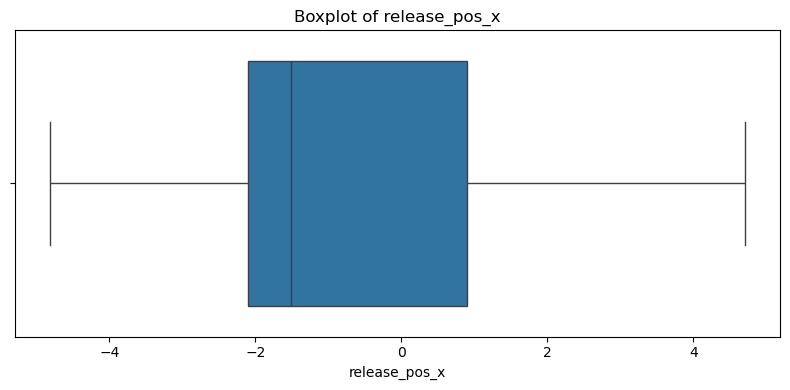

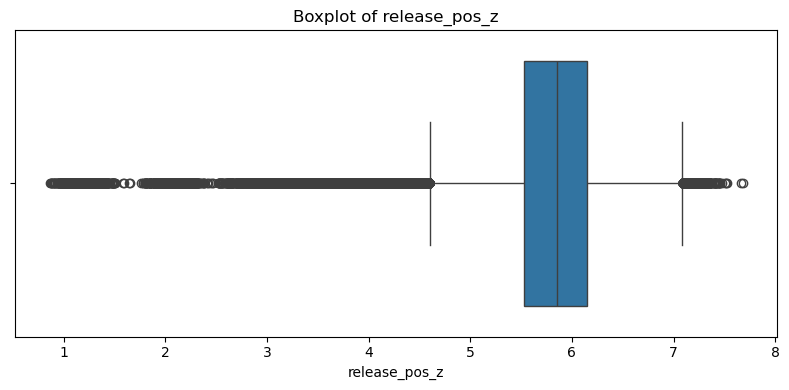

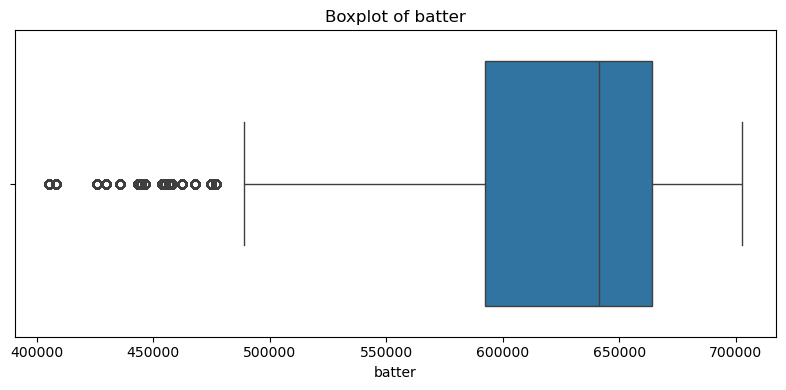

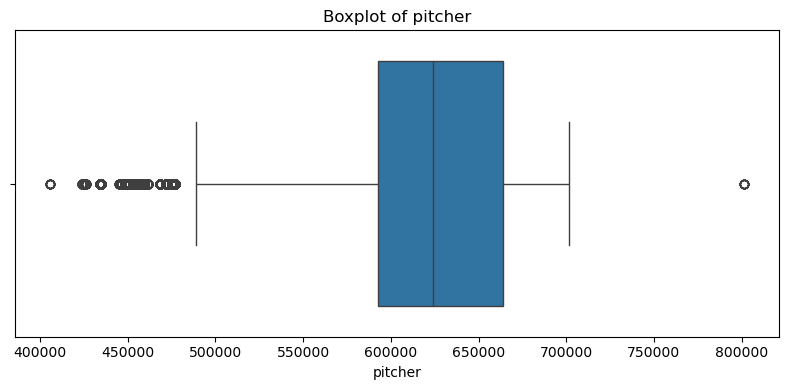

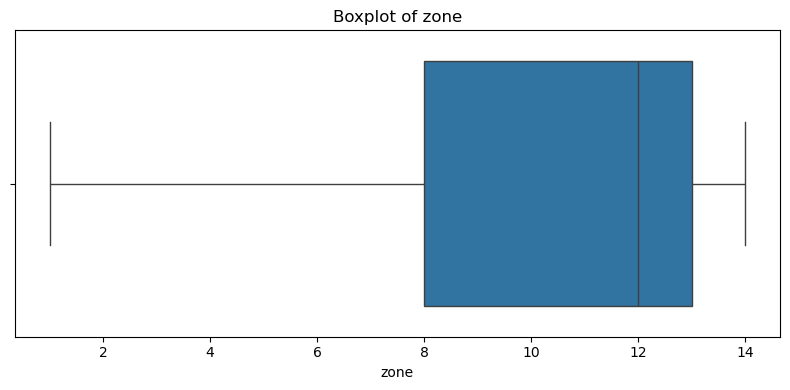

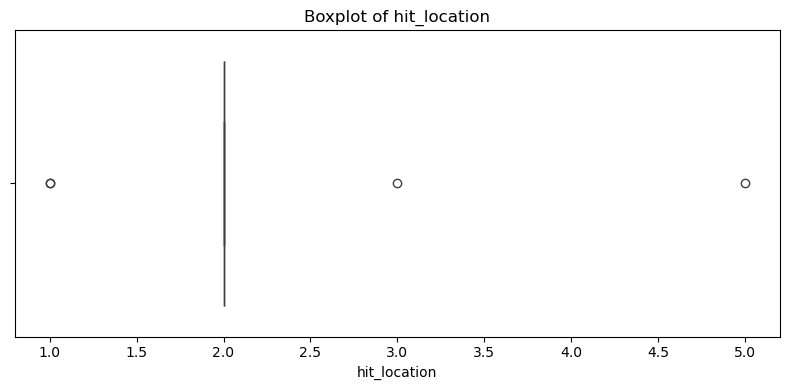

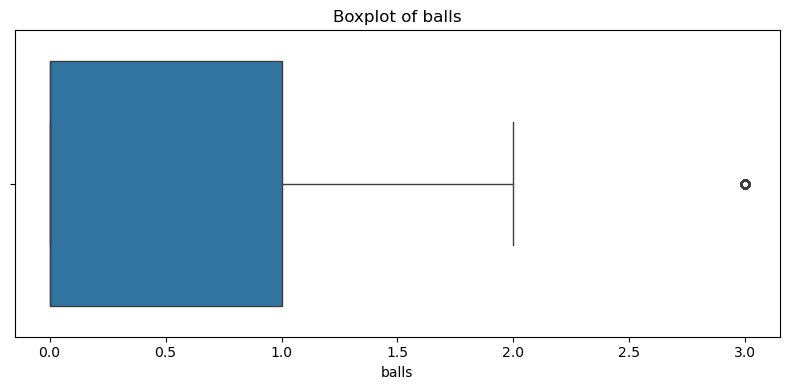

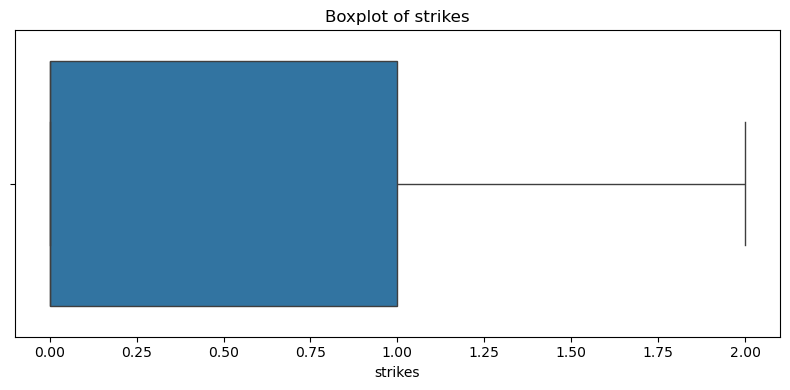

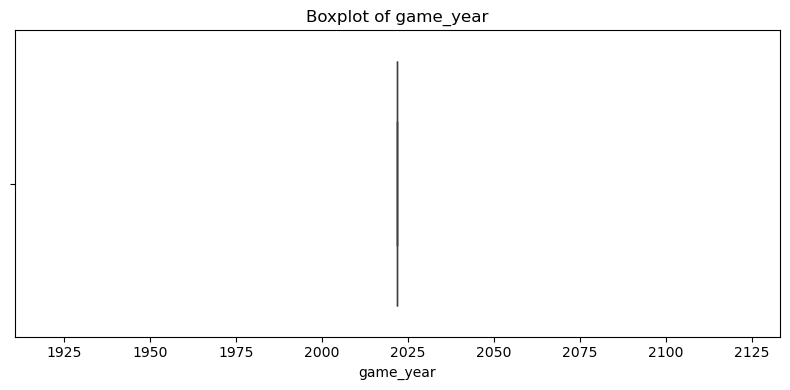

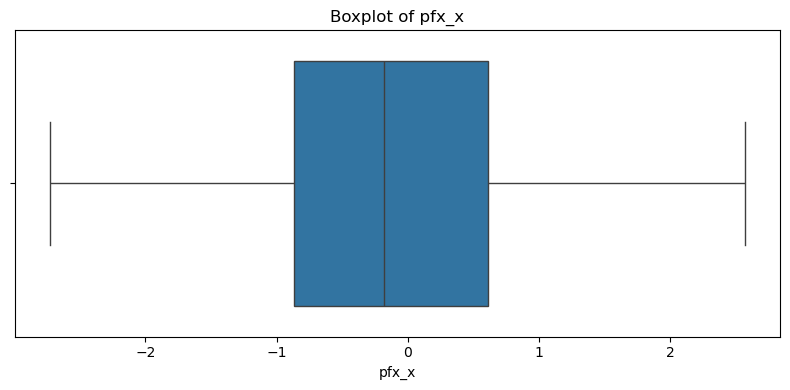

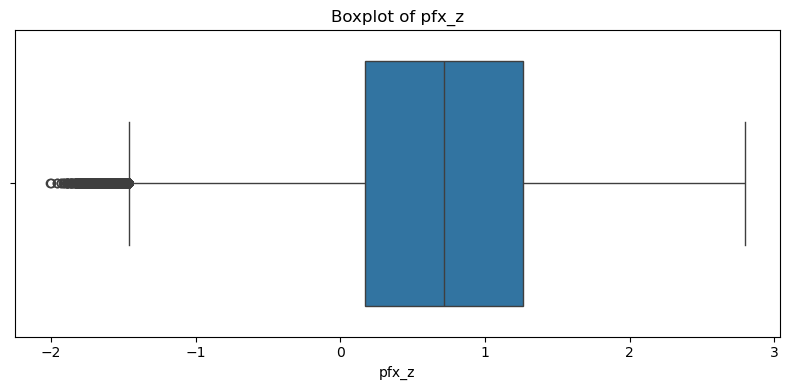

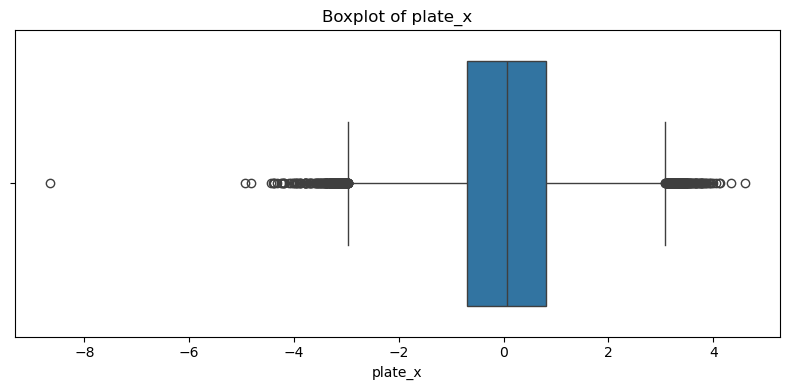

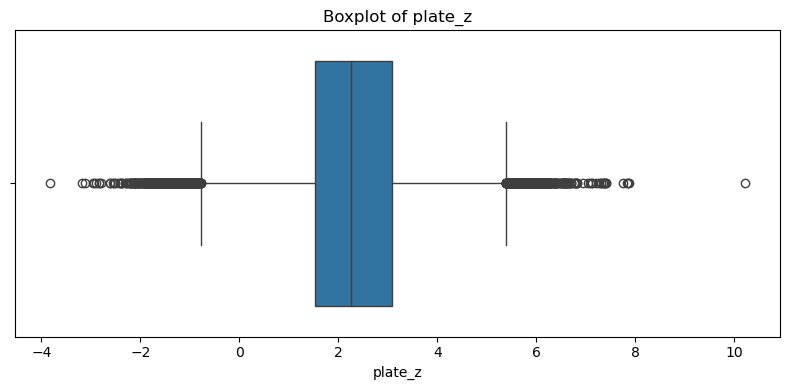

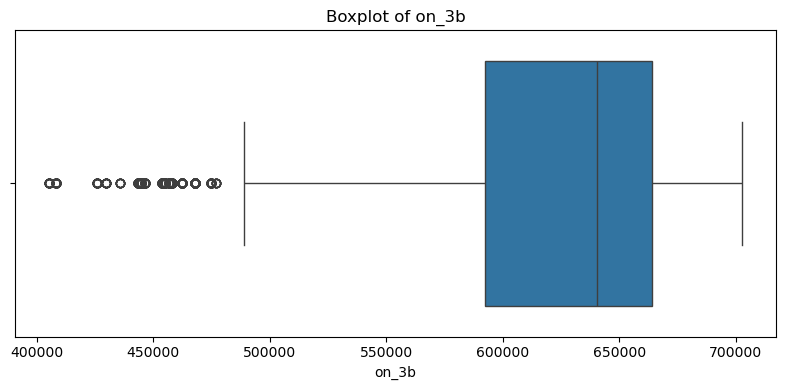

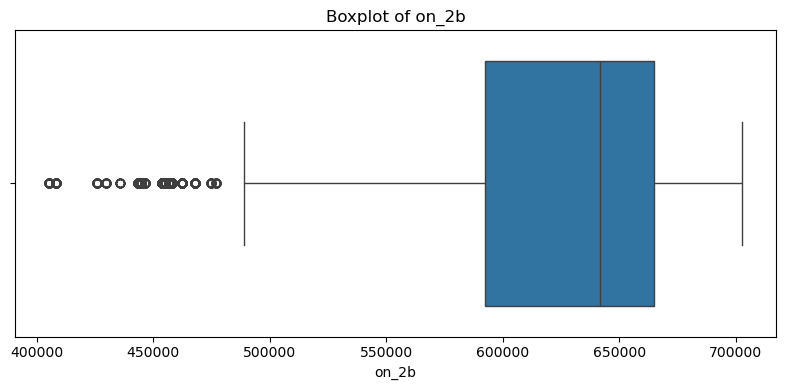

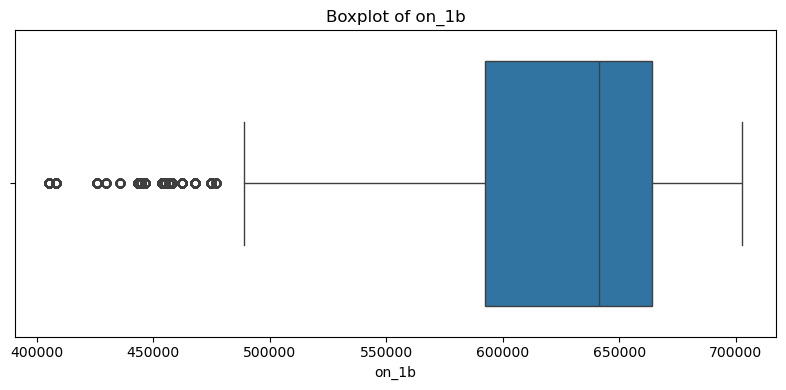

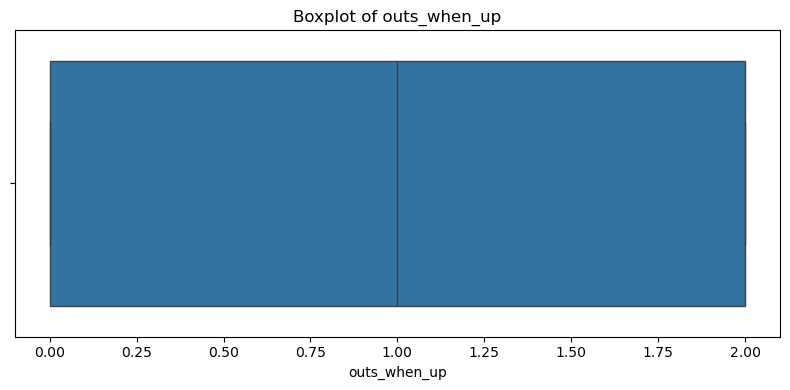

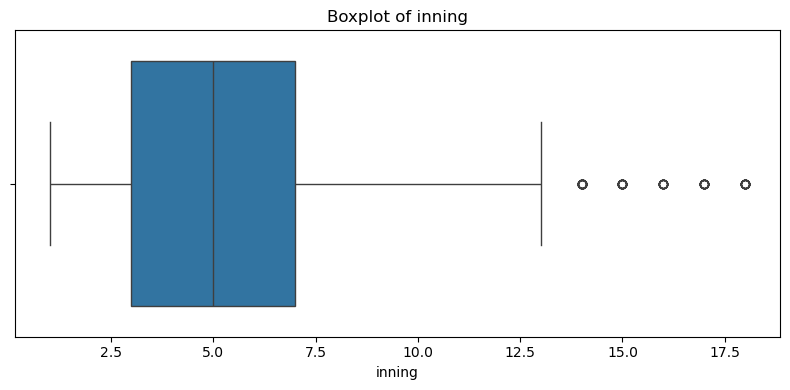

ValueError: List of boxplot statistics and `positions` values must have same the length

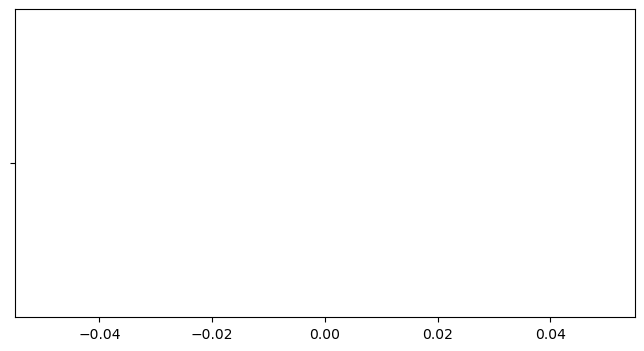

In [55]:
numeric_features = df.select_dtypes(include=[np.number])

for col in numeric_features.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

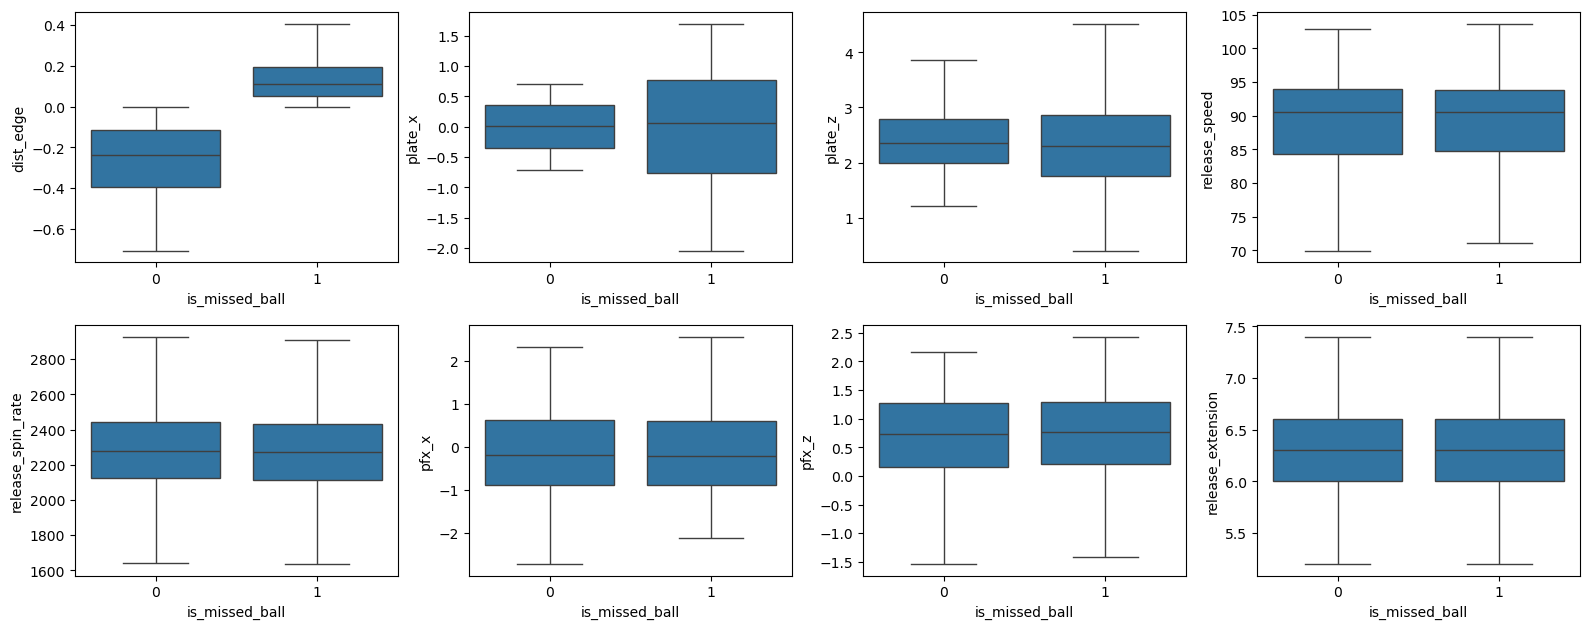

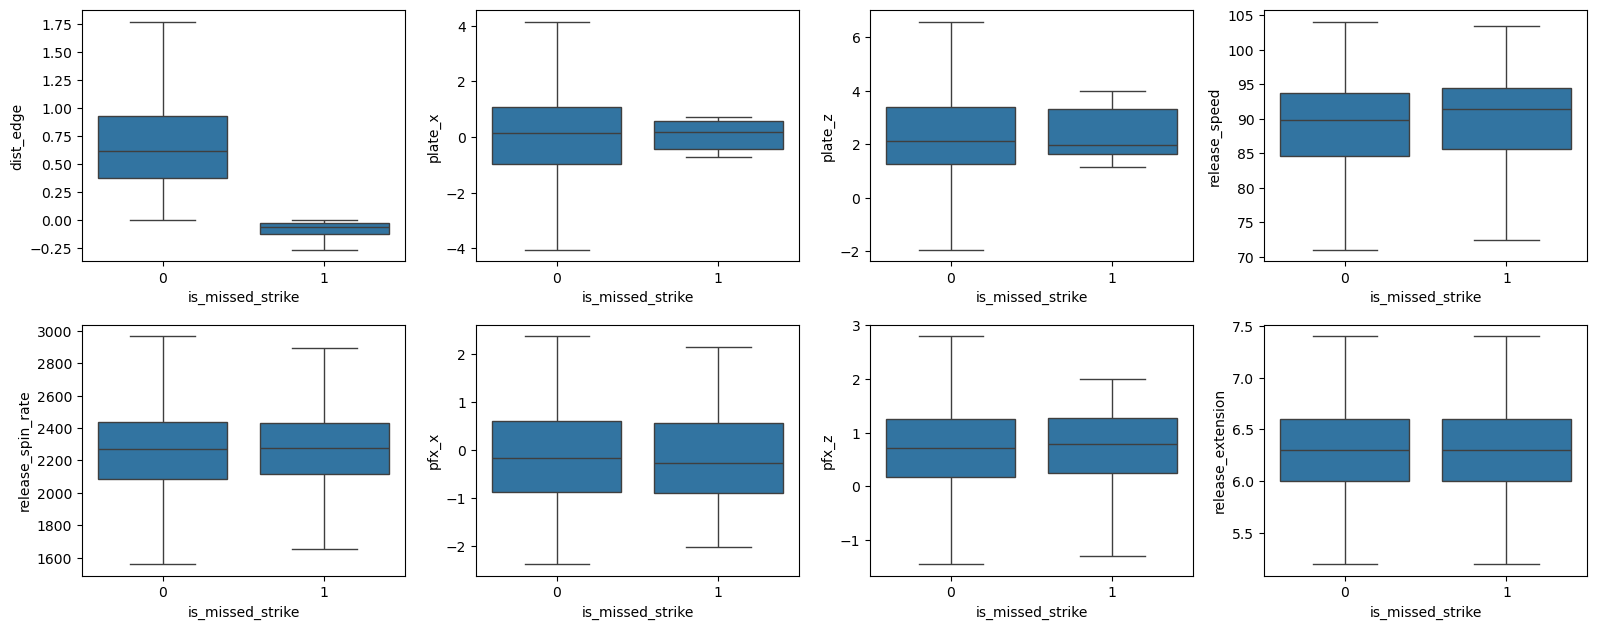

In [38]:
def box_by_response(target, feats, data, ncols=4):
    nrows = int(np.ceil(len(feats)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.2*nrows))
    for a, f in zip(axes.ravel(), feats):
        sns.boxplot(data=data, x=target, y=f, ax=a, showfliers=False)
    for a in axes.ravel()[len(feats):]: a.axis("off")
    plt.tight_layout()

sub_cs = df[df["call"] == "called_strike"]   # population for is_missed_ball
sub_cb = df[df["call"] == "ball"]     # population for is_missed_strike

feats_box = ["dist_edge","plate_x","plate_z","release_speed",
             "release_spin_rate","pfx_x","pfx_z","release_extension"]
box_by_response("is_missed_ball", feats_box, sub_cs)
box_by_response("is_missed_strike", feats_box, sub_cb)

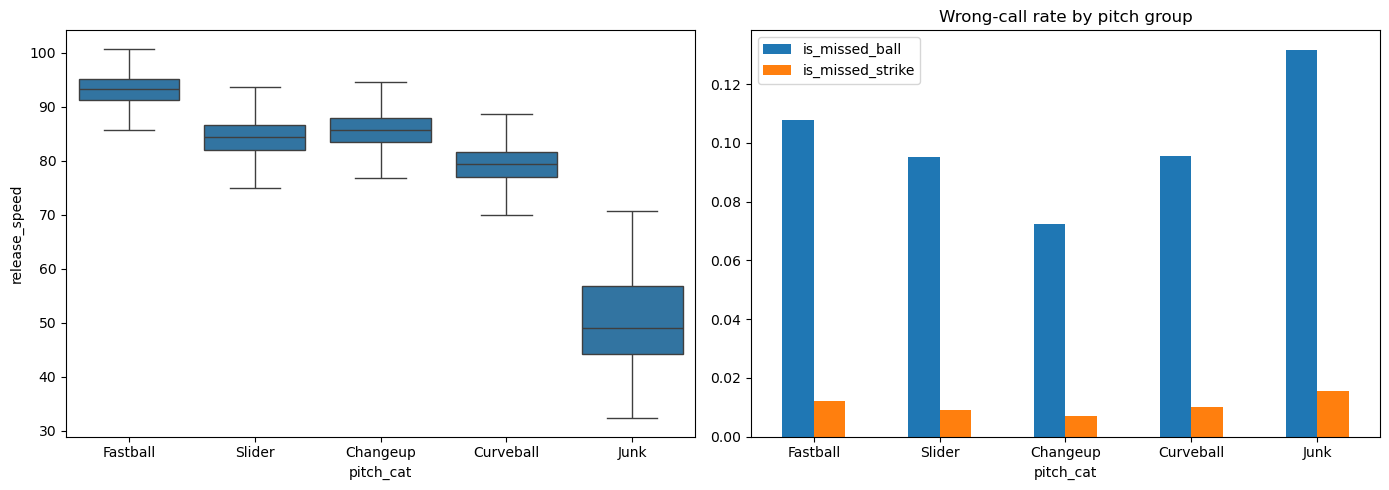

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = ["Fastball", "Slider","Changeup","Curveball","Junk"] 
sns.boxplot(data=df, x="pitch_cat", y="release_speed", ax=ax[0], showfliers=False,order=order)
df.groupby("pitch_cat")[resp].mean().reindex(order).plot.bar(ax=ax[1], rot=0, title="Wrong-call rate by pitch group")
plt.tight_layout()

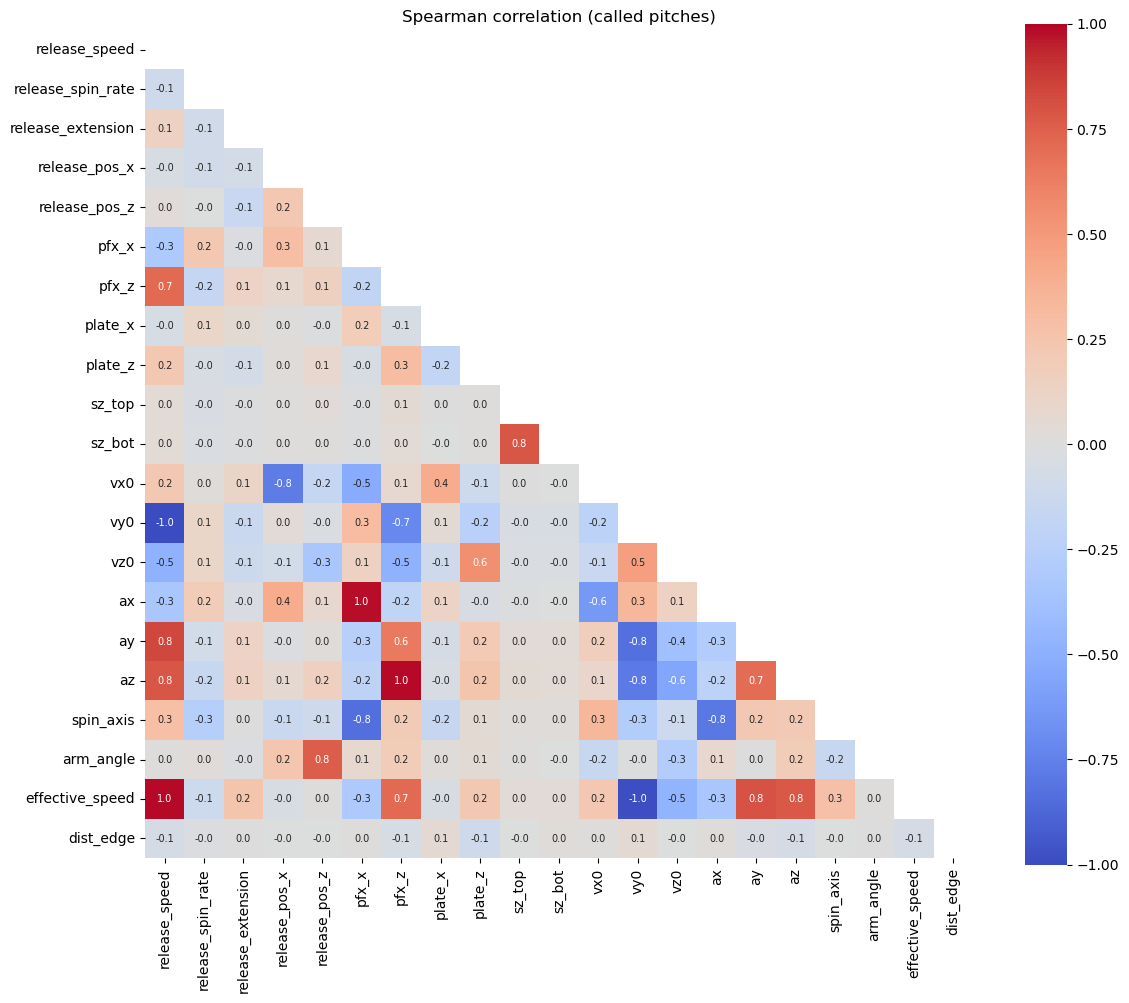

In [43]:
phys = ["release_speed","release_spin_rate","release_extension","release_pos_x","release_pos_z",
        "pfx_x","pfx_z","plate_x","plate_z","sz_top","sz_bot","vx0","vy0","vz0","ax","ay","az",
        "spin_axis","arm_angle","effective_speed","dist_edge"]

corr = df[phys].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, square=True)
plt.title("Spearman correlation (called pitches)"); plt.tight_layout()


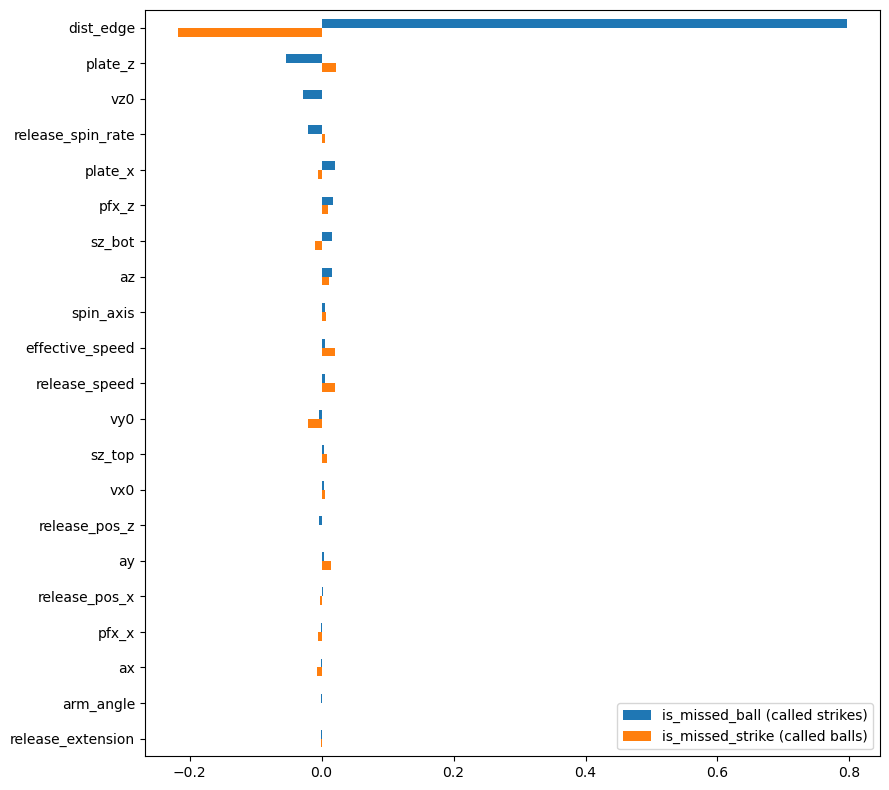

In [44]:
tc = pd.DataFrame({
    "is_missed_ball (called strikes)": sub_cs[phys].corrwith(sub_cs["is_missed_ball"].astype(float), method="spearman"),
    "is_missed_strike (called balls)": sub_cb[phys].corrwith(sub_cb["is_missed_strike"].astype(float), method="spearman"),
}).sort_values(by="is_missed_ball (called strikes)", key=abs, ascending=False)

tc.plot.barh(figsize=(9, 8)); plt.gca().invert_yaxis(); plt.tight_layout()

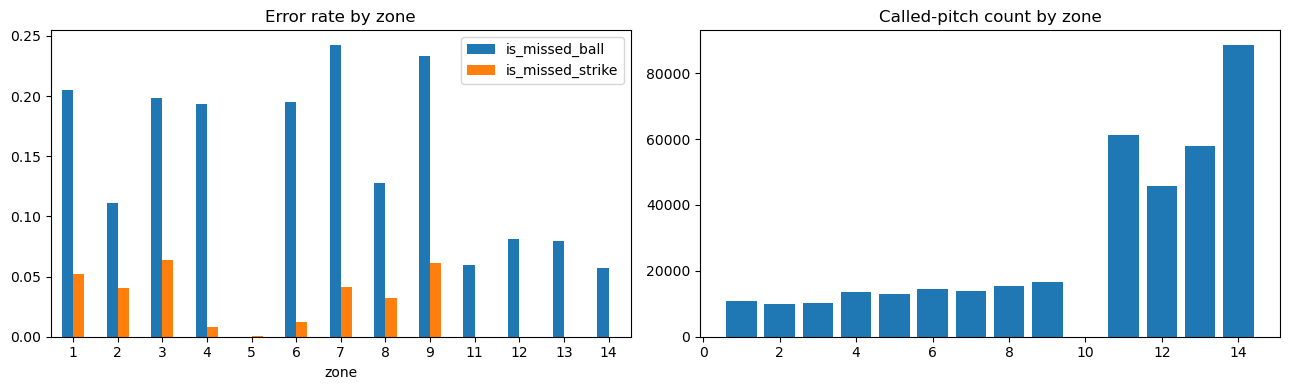

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
zr = df.groupby("zone")[resp].mean()
zr.plot.bar(ax=ax[0], rot=0, title="Error rate by zone")
ax[0].set_xticklabels([int(z) for z in zr.index])
n = df.groupby("zone").size()
ax[1].bar(n.index.astype(int), n.values); ax[1].set_title("Called-pitch count by zone")
plt.tight_layout()

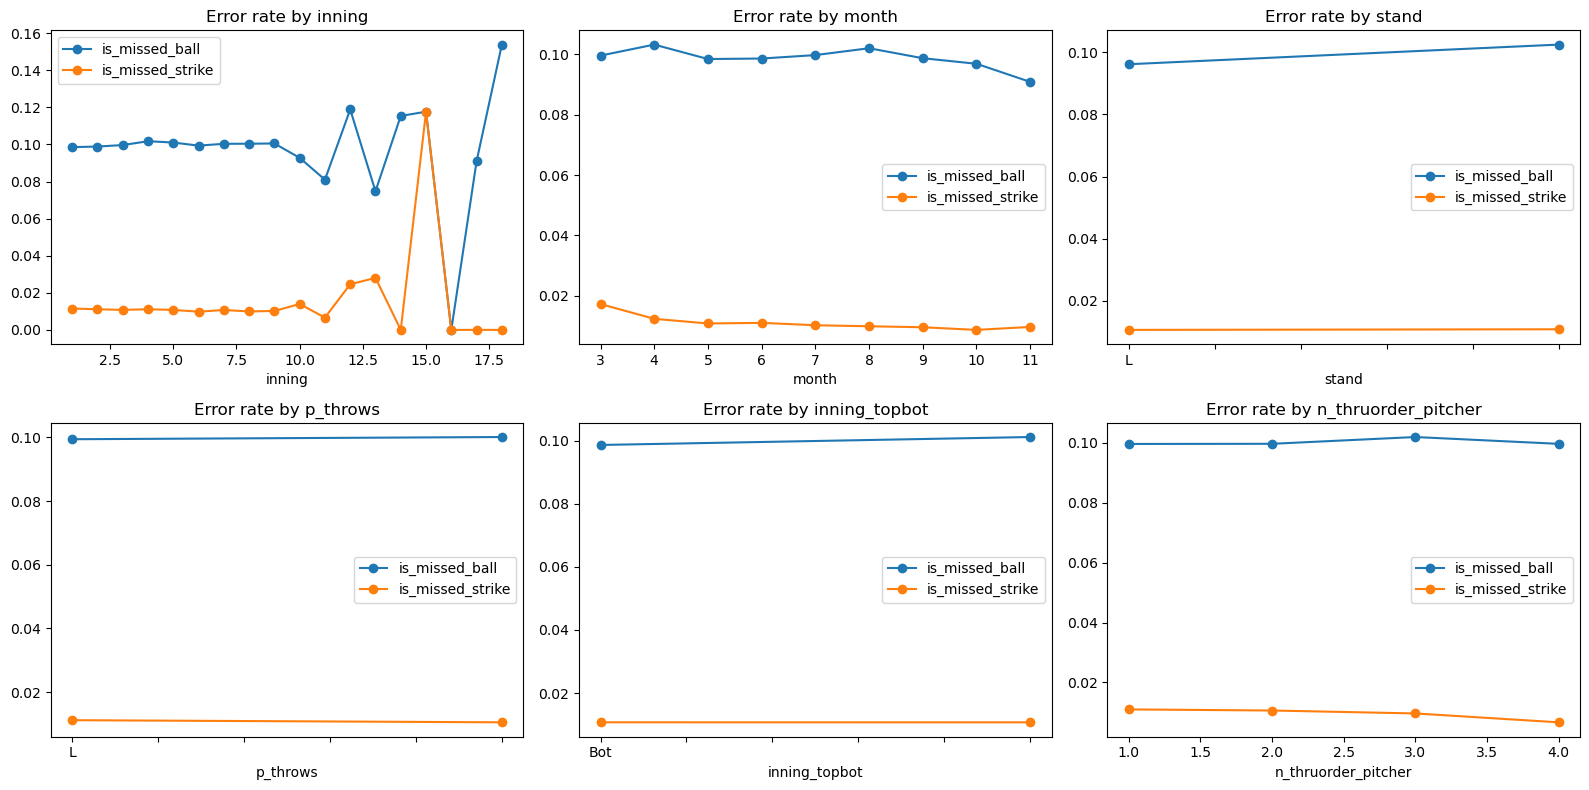

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(axes.ravel(), ["inning","month","stand","p_throws","inning_topbot","n_thruorder_pitcher"]):
    df.groupby(c)[resp].mean().plot(ax=a, marker="o", title=f"Error rate by {c}")
plt.tight_layout()

In [50]:
for name, col in [("pitcher","pitcher"), ("catcher","fielder_2"), ("batter","batter")]:
    r = df.groupby(col).agg(n=("wrong_call","size"), wrong=("wrong_call","mean"))
    r = r[r["n"] >= 200]
    print(name, len(r), r["wrong"].describe().round(3).to_dict())

pitcher 530 {'count': 530.0, 'mean': 0.11, 'std': 0.018, 'min': 0.059, '25%': 0.098, '50%': 0.109, '75%': 0.121, 'max': 0.184}
catcher 110 {'count': 110.0, 'mean': 0.109, 'std': 0.01, 'min': 0.084, '25%': 0.104, '50%': 0.109, '75%': 0.116, 'max': 0.13}
batter 477 {'count': 477.0, 'mean': 0.11, 'std': 0.016, 'min': 0.064, '25%': 0.101, '50%': 0.11, '75%': 0.12, 'max': 0.171}


In [51]:
rows = []
for f in phys:
    for t, d in [("is_missed_ball", sub_cs), ("is_missed_strike", sub_cb)]:
        a = d.loc[d[t] == 1, f].dropna(); b = d.loc[d[t] == 0, f].dropna()
        u = stats.mannwhitneyu(a, b)
        rows.append({"feature": f, "target": t, "p": u.pvalue,
                     "auc": u.statistic/(len(a)*len(b))})   # P(feature_wrong > feature_right)
mw = pd.DataFrame(rows)
mw["sep"] = (mw["auc"] - 0.5).abs()
print(mw.sort_values("sep", ascending=False).head(15))

for t, d in [("is_missed_ball", sub_cs), ("is_missed_strike", sub_cb)]:
    print(t, "stand chi2 p =", stats.chi2_contingency(pd.crosstab(d["stand"], d[t]))[1])

            feature            target             p       auc       sep
41        dist_edge  is_missed_strike  0.000000e+00  0.000000  0.500000
40        dist_edge    is_missed_ball  0.000000e+00  1.000000  0.500000
17          plate_z  is_missed_strike  1.856963e-27  0.550080  0.050080
1     release_speed  is_missed_strike  4.039204e-25  0.547758  0.047758
25              vy0  is_missed_strike  7.326279e-25  0.452505  0.047495
39  effective_speed  is_missed_strike  1.903126e-24  0.547229  0.047229
31               ay  is_missed_strike  1.261945e-13  0.534182  0.034182
16          plate_z    is_missed_ball  5.018115e-80  0.466002  0.033998
33               az  is_missed_strike  1.797795e-08  0.525972  0.025972
21           sz_bot  is_missed_strike  7.178026e-07  0.477136  0.022864
13            pfx_z  is_missed_strike  1.481841e-06  0.522205  0.022205
19           sz_top  is_missed_strike  4.311548e-05  0.518867  0.018867
26              vz0    is_missed_ball  1.109680e-22  0.482409  0

In [52]:
Xc = df[phys].dropna().corr().values
vif = pd.Series(np.diag(np.linalg.inv(Xc)), index=phys).sort_values(ascending=False)
print(vif.round(1))

vy0                  6874.4
release_speed        3921.0
effective_speed      3864.7
vx0                   478.2
vz0                   272.5
release_pos_x         249.7
plate_z               159.5
ax                    118.7
az                     94.0
pfx_z                  90.1
pfx_x                  81.8
plate_x                78.2
release_extension      48.8
release_pos_z          45.2
ay                     34.5
arm_angle               4.2
spin_axis               3.7
sz_top                  2.8
sz_bot                  2.8
release_spin_rate       1.3
dist_edge               1.1
dtype: float64
